# 2.2.2. Bài làm mẫu - Bài toán 2: SVM nhận diện chữ số

PDF gọi tên MNIST nhưng mã dùng **load_digits**: 1.797 ảnh 8×8, 64 đặc trưng, mức xám 0-16. Notebook dùng đúng Digits như mã trong tài liệu, không gọi đây là MNIST 28×28. File sample_submission.csv chỉ là mẫu nộp kết quả, không chứa pixel ảnh và không dùng huấn luyện.

## Nhiệm vụ 1. Biểu diễn và hiển thị ảnh

### Bước 1. Import và nạp dữ liệu

In [1]:
from pathlib import Path
from time import perf_counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn import svm, datasets
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score,
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning

get_ipython().run_line_magic('matplotlib', 'inline')
plt.rcParams['figure.dpi'] = 120
RANDOM_STATE = 101
# Bao loi neu bo giai chua hoi tu, tranh su dung ket qua huan luyen dang do.
warnings.filterwarnings('error', category=ConvergenceWarning)


lab_candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    lab_candidates.extend([parent, parent / 'Lab05' / '2.2. Giai_Thuat2'])
# Duong dan du an duoc chi dinh; dung khi mo ban notebook tu thu muc outputs.
lab_candidates.append(Path(r'D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2'))
LAB_DIR = next((p for p in lab_candidates if (p / 'data' / 'Iris.csv').is_file()), None)
if LAB_DIR is None:
    raise FileNotFoundError('Chua tim thay thu muc data cua Lab05/2.2. Giai_Thuat2.')
DATA_DIR = LAB_DIR / 'data'
print('Thu muc du lieu:', DATA_DIR)

Thu muc du lieu: D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2\data


In [2]:
digits=datasets.load_digits(n_class=10)
X=pd.DataFrame(digits.data,columns=[f'pixel_{i}' for i in range(64)])
y=pd.Series(digits.target,name='digit')
CLASS_NAMES=[str(i) for i in range(10)]
RESULT_SLUG='Bai_mau_Digits'
SCORING='accuracy'
print('X:',X.shape,'| Images:',digits.images.shape,'| Pixel range:',digits.data.min(),digits.data.max())
print('Anh dau dang ma tran 8x8:')
display(pd.DataFrame(digits.data[0].reshape(8,8)))
print('9 nhan dau:',digits.target[:9])

X: (1797, 64) | Images: (1797, 8, 8) | Pixel range: 0.0 16.0
Anh dau dang ma tran 8x8:


,0,1,2,3,4,5,6,7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0
1,0.0,0.0,13.0,15.0,10.0,15.0,5.0,0.0
2,0.0,3.0,15.0,2.0,0.0,11.0,8.0,0.0
3,0.0,4.0,12.0,0.0,0.0,8.0,8.0,0.0
4,0.0,5.0,8.0,0.0,0.0,9.0,8.0,0.0
5,0.0,4.0,11.0,0.0,1.0,12.0,7.0,0.0
6,0.0,2.0,14.0,5.0,10.0,12.0,0.0,0.0
7,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0


9 nhan dau: [0 1 2 3 4 5 6 7 8]


### Bước 2. Hiển thị 64 ảnh và một ảnh riêng

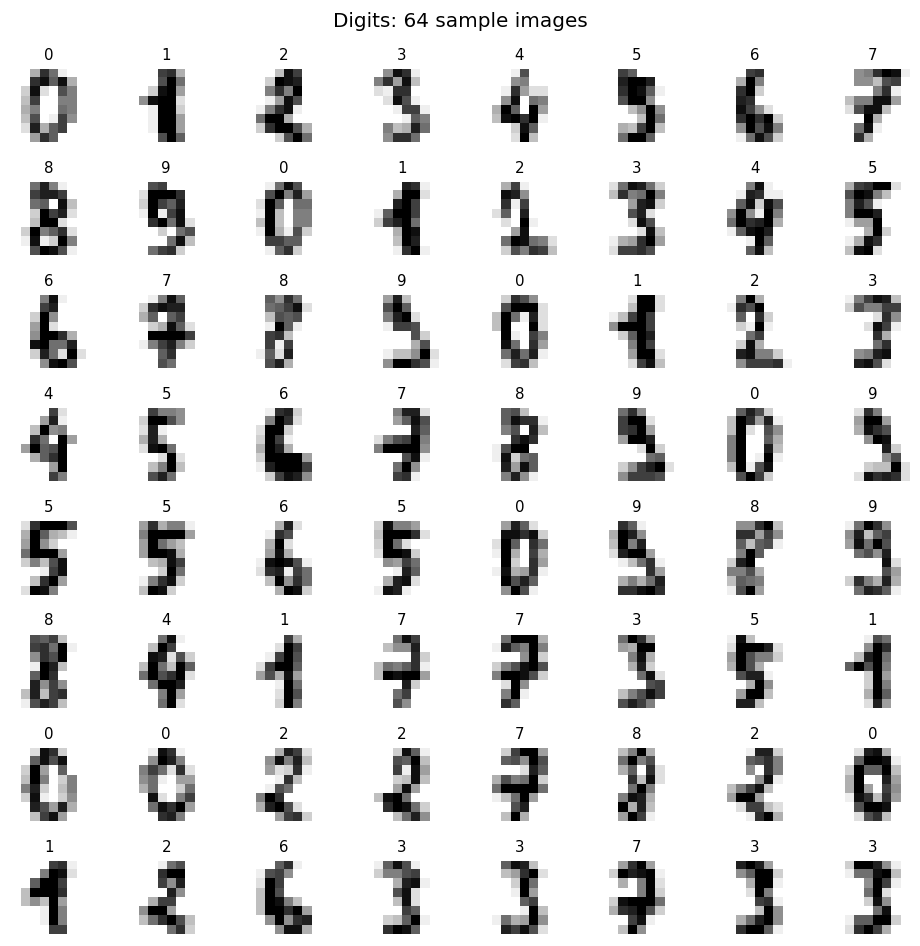

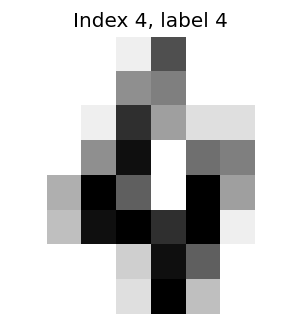

In [3]:
fig,axes=plt.subplots(8,8,figsize=(8,8))
for index,ax in enumerate(axes.flat):
    ax.imshow(digits.images[index],cmap='gray_r',vmin=0,vmax=16)
    ax.set_title(str(digits.target[index]),fontsize=9)
    ax.axis('off')
plt.suptitle('Digits: 64 sample images')
plt.tight_layout()
plt.show()

def view_digit(index):
    fig,ax=plt.subplots(figsize=(3,3))
    ax.imshow(digits.images[index],cmap='gray_r',vmin=0,vmax=16)
    ax.set_title(f'Index {index}, label {digits.target[index]}')
    ax.axis('off')
    plt.show()
view_digit(4)

## Nhiệm vụ 2. Xây dựng và đánh giá SVM

### Bước 1. Chuẩn bị dữ liệu và mô hình

Theo cách chia liên tiếp của bài mẫu: 1.500 mẫu đầu làm train, **từ chỉ số 1500** đến hết làm test (297 mẫu). Sửa mốc 1501 trong PDF để không bỏ sót mẫu. Baseline giữ SVC(C=100, gamma=0.001) trên pixel gốc. Phần tìm kiếm thêm StandardScaler trong Pipeline và chọn tham số chỉ bằng CV trên train.

In [4]:
X_train,X_test=X.iloc[:1500].copy(),X.iloc[1500:].copy()
y_train,y_test=y.iloc[:1500].copy(),y.iloc[1500:].copy()
assert len(X_train)+len(X_test)==len(X) and set(X_train.index).isdisjoint(X_test.index)
cv_splitter=StratifiedKFold(n_splits=4,shuffle=True,random_state=RANDOM_STATE)
print('Train:',X_train.shape,'| Test:',X_test.shape)
baseline=Pipeline([('scale','passthrough'),('svc',svm.SVC(C=100,gamma=0.001,kernel='rbf'))])

t0 = perf_counter()
baseline.fit(X_train, y_train)
print('Train accuracy (baseline):', round(baseline.score(X_train, y_train), 4))
print('Thoi gian fit baseline:', round(perf_counter() - t0, 2), 'giay')

Train: (1500, 64) | Test: (297, 64)


Train accuracy (baseline): 1.0
Thoi gian fit baseline: 0.41 giay


### Bước 2. Tìm C và gamma bằng CV

Baseline trong PDF dùng pixel gốc. Lưới bổ sung bên dưới thử scaling passthrough hoặc StandardScaler để chọn cùng với C/gamma trên train. Khi thay cách scaling, gamma phù hợp có thể thay đổi; không dùng gamma của pixel thô một cách máy móc cho dữ liệu đã chuẩn hóa.

Scoring: accuracy
Baseline mean CV: 0.994
Tham so tot nhat: {'scale': 'passthrough', 'svc__C': 10, 'svc__gamma': 0.001}
Mean CV tot nhat: 0.994
Thoi gian tim kiem: 25.44 giay


,params,mean_train_score,mean_test_score,std_test_score,mean_fit_time
4,"{'scale': 'passthrough', 'svc__C': 10, 'svc__g...",1.000000,0.994000,0.004761,0.113294
7,"{'scale': 'passthrough', 'svc__C': 100, 'svc__...",1.000000,0.994000,0.004761,0.073678
3,"{'scale': 'passthrough', 'svc__C': 10, 'svc__g...",1.000000,0.992000,0.004619,0.067837
6,"{'scale': 'passthrough', 'svc__C': 100, 'svc__...",1.000000,0.992000,0.004619,0.055285
1,"{'scale': 'passthrough', 'svc__C': 1, 'svc__ga...",0.999333,0.991333,0.005121,0.106456
0,"{'scale': 'passthrough', 'svc__C': 1, 'svc__ga...",0.997333,0.988000,0.004807,0.074047
11,"{'scale': StandardScaler(), 'svc__C': 1, 'svc_...",0.996000,0.984667,0.006074,0.059830
15,"{'scale': StandardScaler(), 'svc__C': 100, 'sv...",1.000000,0.984667,0.003464,0.090904
14,"{'scale': StandardScaler(), 'svc__C': 10, 'svc...",1.000000,0.984667,0.002211,0.059545
12,"{'scale': StandardScaler(), 'svc__C': 10, 'svc...",1.000000,0.984667,0.003464,0.082730


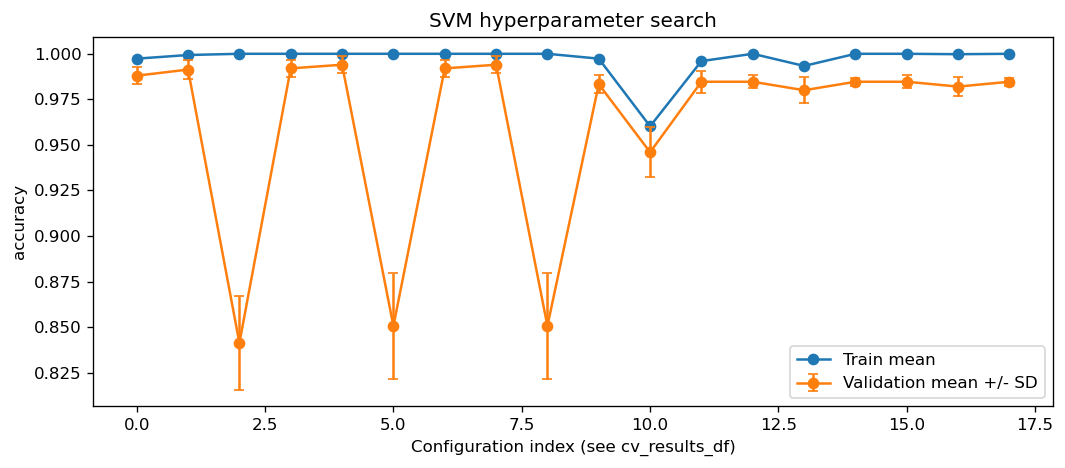

In [5]:
# Buoc scale cua baseline cho phep GridSearchCV lua chon scaling.
param_grid={
    'scale':['passthrough',StandardScaler()],
    'svc__C':[1,10,100],
    'svc__gamma':['scale',0.001,0.01]
}

# Khong dung test de chon kernel hay tham so.
t0 = perf_counter()
baseline_cv_scores = cross_val_score(
    baseline, X_train, y_train, cv=cv_splitter, scoring=SCORING, n_jobs=1, error_score='raise'
)
search = GridSearchCV(
    clone(baseline), param_grid=param_grid, scoring=SCORING, cv=cv_splitter,
    refit=True, return_train_score=True, error_score='raise', n_jobs=1
)
search.fit(X_train, y_train)
best_svm = search.best_estimator_
cv_results_df = pd.DataFrame(search.cv_results_)
print('Scoring:', SCORING)
print('Baseline mean CV:', round(baseline_cv_scores.mean(), 4))
print('Tham so tot nhat:', search.best_params_)
print('Mean CV tot nhat:', round(search.best_score_, 4))
print('Thoi gian tim kiem:', round(perf_counter()-t0, 2), 'giay')
display(cv_results_df[['params', 'mean_train_score', 'mean_test_score',
                       'std_test_score', 'mean_fit_time']].sort_values('mean_test_score', ascending=False).head(12))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(len(cv_results_df)), cv_results_df['mean_train_score'], 'o-', label='Train mean')
ax.errorbar(np.arange(len(cv_results_df)), cv_results_df['mean_test_score'],
            yerr=cv_results_df['std_test_score'], fmt='o-', capsize=3, label='Validation mean +/- SD')
ax.set(xlabel='Configuration index (see cv_results_df)', ylabel=SCORING, title='SVM hyperparameter search')
ax.legend()
plt.tight_layout()
plt.show()

### Bước 3. Confusion matrix và classification report

Thứ tự đúng là **y_true trước, y_pred sau**. PDF đảo hai đối số trong một số dòng; notebook dùng đúng thứ tự để precision/recall có ý nghĩa. Confusion matrix có hàng là nhãn thật, cột là nhãn dự đoán.


SVM baseline
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        27
           1       0.94      1.00      0.97        31
           2       1.00      1.00      1.00        27
           3       1.00      0.80      0.89        30
           4       0.97      0.91      0.94        33
           5       0.91      1.00      0.95        30
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.84      0.93      0.88        28
           9       0.91      0.94      0.92        31

    accuracy                           0.95       297
   macro avg       0.96      0.95      0.95       297
weighted avg       0.96      0.95      0.95       297




SVM tuned
              precision    recall  f1-score   support

           0       1.00      0.96      0.98        27
           1       0.94      1.00      0.97        31
           2       1.00      1.00      1.00        27
           3       1.00      0.80      0.89        30
           4       0.97      0.91      0.94        33
           5       0.91      1.00      0.95        30
           6       1.00      1.00      1.00        30
           7       1.00      1.00      1.00        30
           8       0.84      0.93      0.88        28
           9       0.91      0.94      0.92        31

    accuracy                           0.95       297
   macro avg       0.96      0.95      0.95       297
weighted avg       0.96      0.95      0.95       297



,Train accuracy,CV score,Test accuracy,Test balanced accuracy,Test precision macro,Test recall macro,Test F1 macro
Model,,,,,,,
SVM baseline,1.0,0.994,0.9529,0.9536,0.9561,0.9536,0.9531
SVM tuned,1.0,0.994,0.9529,0.9536,0.9561,0.9536,0.9531


Accuracy neu luon doan lop pho bien: 0.1111


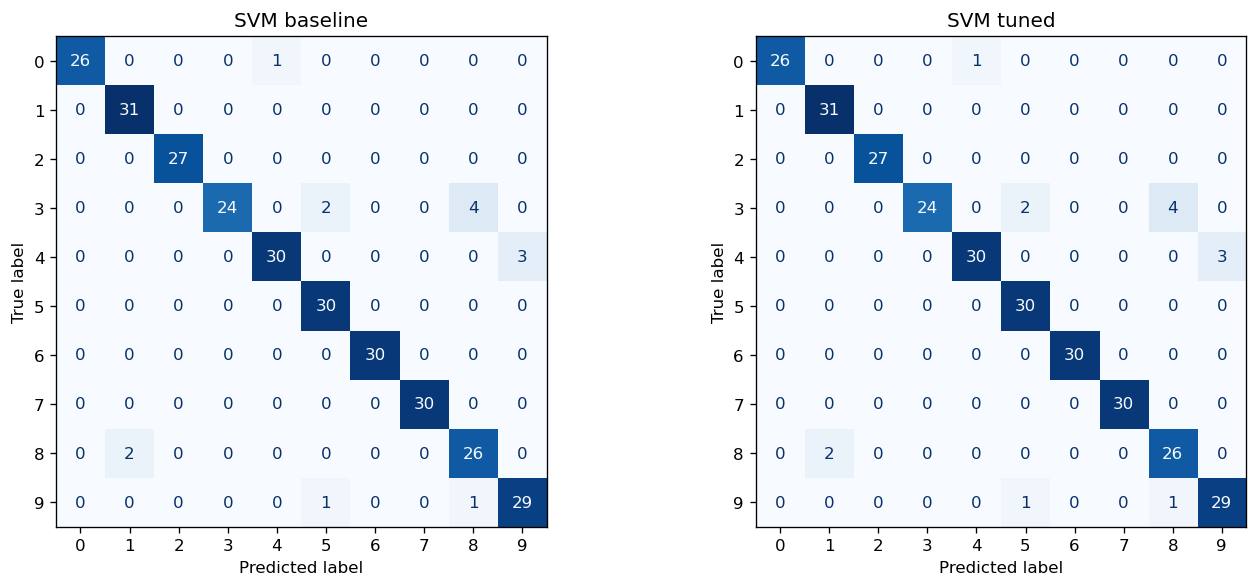

In [6]:
# Danh gia mot lan sau khi chot cau hinh bang CV.
models = {'SVM baseline': baseline, 'SVM tuned': best_svm}
cv_scores = {'SVM baseline': baseline_cv_scores.mean(), 'SVM tuned': search.best_score_}
labels = sorted(pd.unique(y))
is_binary = len(labels) == 2
minority_label = y_train.value_counts().idxmin() if is_binary else None
records, predictions, decision_scores = [], {}, {}

for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    row = {
        'Model': name, 'Train accuracy': model.score(X_train, y_train),
        'CV score': cv_scores[name], 'Test accuracy': accuracy_score(y_test, pred),
        'Test balanced accuracy': balanced_accuracy_score(y_test, pred),
        'Test precision macro': precision_score(y_test, pred, average='macro', zero_division=0),
        'Test recall macro': recall_score(y_test, pred, average='macro', zero_division=0),
        'Test F1 macro': f1_score(y_test, pred, average='macro', zero_division=0)
    }
    if is_binary:
        scores = model.decision_function(X_test)
        decision_scores[name] = scores
        minority_scores = scores if minority_label == model.classes_[1] else -scores
        row['Test ROC AUC (class 1)'] = roc_auc_score(y_test, scores)
        row['Minority label'] = minority_label
        row['Minority precision'] = precision_score(y_test, pred, pos_label=minority_label, zero_division=0)
        row['Minority recall'] = recall_score(y_test, pred, pos_label=minority_label, zero_division=0)
        row['Minority average precision'] = average_precision_score((y_test==minority_label).astype(int), minority_scores)
    records.append(row)
    print('\n' + name)
    print(classification_report(y_test, pred, labels=labels, target_names=CLASS_NAMES, zero_division=0))

comparison_df = pd.DataFrame(records).set_index('Model')
display(comparison_df.round(4))
majority_baseline = y_test.value_counts(normalize=True).max()
print('Accuracy neu luon doan lop pho bien:', round(majority_baseline, 4))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5 if len(labels)<=3 else 5))
for ax, name in zip(axs, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], labels=labels, display_labels=CLASS_NAMES,
        cmap='Blues', colorbar=False, ax=ax, xticks_rotation=45 if len(labels)==3 else 0
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

if is_binary:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, model in models.items():
        scores = decision_scores[name]
        RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
        minority_scores = scores if minority_label==model.classes_[1] else -scores
        PrecisionRecallDisplay.from_predictions(
            (y_test==minority_label).astype(int), minority_scores, name=name, ax=axes[1]
        )
    axes[0].plot([0, 1], [0, 1], '--', color='gray')
    axes[0].set_title('Test ROC (positive class = 1)')
    axes[1].set_title(f'Test precision-recall (class {minority_label})')
    plt.tight_layout()
    plt.show()

### Bước 4. Xem một số dự đoán trên ảnh test

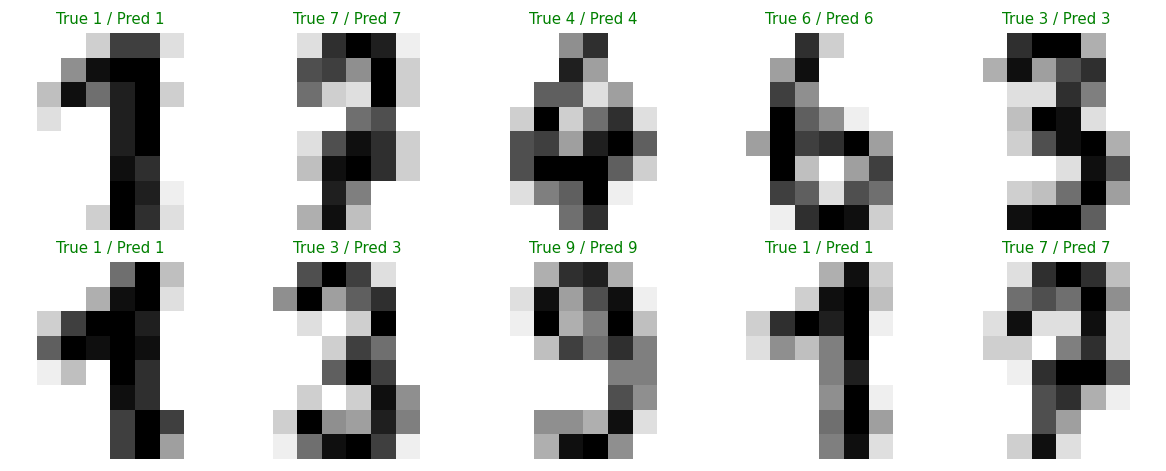

In [7]:
predictions_digits=predictions['SVM tuned']
fig,axes=plt.subplots(2,5,figsize=(10,4))
for local_index,ax in enumerate(axes.flat):
    absolute_index=X_test.index[local_index]
    true_label=int(y_test.iloc[local_index])
    pred_label=int(predictions_digits[local_index])
    ax.imshow(digits.images[absolute_index],cmap='gray_r',vmin=0,vmax=16)
    ax.set_title(f'True {true_label} / Pred {pred_label}',
                 color='green' if true_label==pred_label else 'red',fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Nhận xét và lưu kết quả

In [8]:
best_row = cv_results_df.loc[search.best_index_]
gap = float(best_row['mean_train_score'] - best_row['mean_test_score'])
tuned = comparison_df.loc['SVM tuned']
acc = tuned['Test accuracy']
f1 = tuned['Test F1 macro']
balanced_acc = tuned['Test balanced accuracy']
notes = '\n\n'.join([
    '### Nhận xét kết quả',
    f'- Train **{len(X_train):,} mẫu**, test **{len(X_test):,} mẫu**. Siêu tham số được chọn bằng **{SCORING}**, 4-fold CV trên train.',
    f'- Tham số chọn trong lưới: **{search.best_params_}**. Điểm CV **{search.best_score_:.4f}**; chênh lệch train - validation tại cấu hình này **{gap:.4f}**.',
    f'- SVM sau tìm kiếm đạt test accuracy **{acc:.4f}**, balanced accuracy **{balanced_acc:.4f}**, F1-macro **{f1:.4f}**.',
    f'- Nếu luôn đoán lớp phổ biến, accuracy là **{majority_baseline:.4f}**. Cần đọc thêm confusion matrix và chỉ số từng lớp để tránh đánh giá sai khi nhãn mất cân bằng.',
    '- Khoảng cách điểm train/validation là dấu hiệu tham khảo về quá khớp, không đo trực tiếp bias/variance. Cấu hình được chọn chỉ tốt nhất trong lưới đã thử.',
    '- Pipeline chỉ fit scaler/imputer/encoder trên phần train của từng fold. Không chọn lại siêu tham số theo test. SVC/LinearSVC dùng decision_function khi đánh giá ROC AUC; đây là điểm quyết định, không phải xác suất đã hiệu chỉnh.'
])
if is_binary:
    minority_count = int((y_test==minority_label).sum())
    precision_minority = tuned['Minority precision']
    recall_minority = tuned['Minority recall']
    notes += f'\n\n- Lớp ít mẫu là **{minority_label}**, có **{minority_count} mẫu test**. Precision **{precision_minority:.4f}**, recall **{recall_minority:.4f}**.'
display(Markdown(notes))

RESULTS_DIR = LAB_DIR / 'ket_qua' / RESULT_SLUG
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(RESULTS_DIR/'so_sanh_mo_hinh.csv', encoding='utf-8-sig')
cv_results_df.to_csv(RESULTS_DIR/'cv_results.csv', index=False, encoding='utf-8-sig')
prediction_table = pd.DataFrame({'row_index':X_test.index, 'actual':y_test.to_numpy(),
    'baseline_prediction':predictions['SVM baseline'], 'tuned_prediction':predictions['SVM tuned']})
if is_binary:
    prediction_table['baseline_score']=decision_scores['SVM baseline']
    prediction_table['tuned_score']=decision_scores['SVM tuned']
prediction_table.to_csv(RESULTS_DIR/'du_doan_test.csv',index=False,encoding='utf-8-sig')
(RESULTS_DIR/'nhan_xet.md').write_text(notes,encoding='utf-8')
print('Ket qua da luu:',RESULTS_DIR)

### Nhận xét kết quả

- Train **1,500 mẫu**, test **297 mẫu**. Siêu tham số được chọn bằng **accuracy**, 4-fold CV trên train.

- Tham số chọn trong lưới: **{'scale': 'passthrough', 'svc__C': 10, 'svc__gamma': 0.001}**. Điểm CV **0.9940**; chênh lệch train - validation tại cấu hình này **0.0060**.

- SVM sau tìm kiếm đạt test accuracy **0.9529**, balanced accuracy **0.9536**, F1-macro **0.9531**.

- Nếu luôn đoán lớp phổ biến, accuracy là **0.1111**. Cần đọc thêm confusion matrix và chỉ số từng lớp để tránh đánh giá sai khi nhãn mất cân bằng.

- Khoảng cách điểm train/validation là dấu hiệu tham khảo về quá khớp, không đo trực tiếp bias/variance. Cấu hình được chọn chỉ tốt nhất trong lưới đã thử.

- Pipeline chỉ fit scaler/imputer/encoder trên phần train của từng fold. Không chọn lại siêu tham số theo test. SVC/LinearSVC dùng decision_function khi đánh giá ROC AUC; đây là điểm quyết định, không phải xác suất đã hiệu chỉnh.

Ket qua da luu: D:\SGU_HocMay_2026-2027\Lab05\2.2. Giai_Thuat2\ket_qua\Bai_mau_Digits


### Diễn giải cho lần chạy đã lưu

CV chọn không scaling (passthrough), RBF với C=10, gamma=0,001. Baseline và cấu hình sau tìm kiếm cùng đạt 95,29% test (283/297 mẫu), trong khi CV khoảng 99,4%. CV xáo trộn trong 1.500 mẫu train; test là 297 mẫu cuối theo cách chia của PDF, có thể khác độ khó. Không thay cách chia hoặc chọn lại tham số chỉ để nâng điểm test này.

## Tài liệu kỹ thuật

- [Scikit-learn - SVM](https://scikit-learn.org/1.7/modules/svm.html)
- [SVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.SVC.html)
- [LinearSVC](https://scikit-learn.org/1.7/modules/generated/sklearn.svm.LinearSVC.html)
- [GridSearchCV](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.GridSearchCV.html)